In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
# Evaluation
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
# Dimensionality reduction
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

In [16]:


df = pd.read_csv('marketing_campaign.csv', sep='\t')
df.head()



,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [17]:
rows, col = df.shape
print(f"rows = {rows}, col = {col}")


rows = 2240, col = 29


In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

In [20]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


In [22]:
missing = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': df.isnull().mean() * 100
})
display(missing.sort_values(
    by='Missing_Percentage',
    ascending=False
))

,Missing_Count,Missing_Percentage
Income,24,1.071429
ID,0,0.000000
NumDealsPurchases,0,0.000000
Z_Revenue,0,0.000000
Z_CostContact,0,0.000000
Complain,0,0.000000
AcceptedCmp2,0,0.000000
AcceptedCmp1,0,0.000000
AcceptedCmp5,0,0.000000
AcceptedCmp4,0,0.000000


In [23]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [24]:
df.drop_duplicates(inplace=True)

df.reset_index(drop=True, inplace=True)

In [25]:
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

ID: 2240 unique values
Year_Birth: 59 unique values
Education: 5 unique values
Marital_Status: 8 unique values
Income: 1974 unique values
Kidhome: 3 unique values
Teenhome: 3 unique values
Dt_Customer: 663 unique values
Recency: 100 unique values
MntWines: 776 unique values
MntFruits: 158 unique values
MntMeatProducts: 558 unique values
MntFishProducts: 182 unique values
MntSweetProducts: 177 unique values
MntGoldProds: 213 unique values
NumDealsPurchases: 15 unique values
NumWebPurchases: 15 unique values
NumCatalogPurchases: 14 unique values
NumStorePurchases: 14 unique values
NumWebVisitsMonth: 16 unique values
AcceptedCmp3: 2 unique values
AcceptedCmp4: 2 unique values
AcceptedCmp5: 2 unique values
AcceptedCmp1: 2 unique values
AcceptedCmp2: 2 unique values
Complain: 2 unique values
Z_CostContact: 1 unique values
Z_Revenue: 1 unique values
Response: 2 unique values


In [26]:
#Univariate analysis


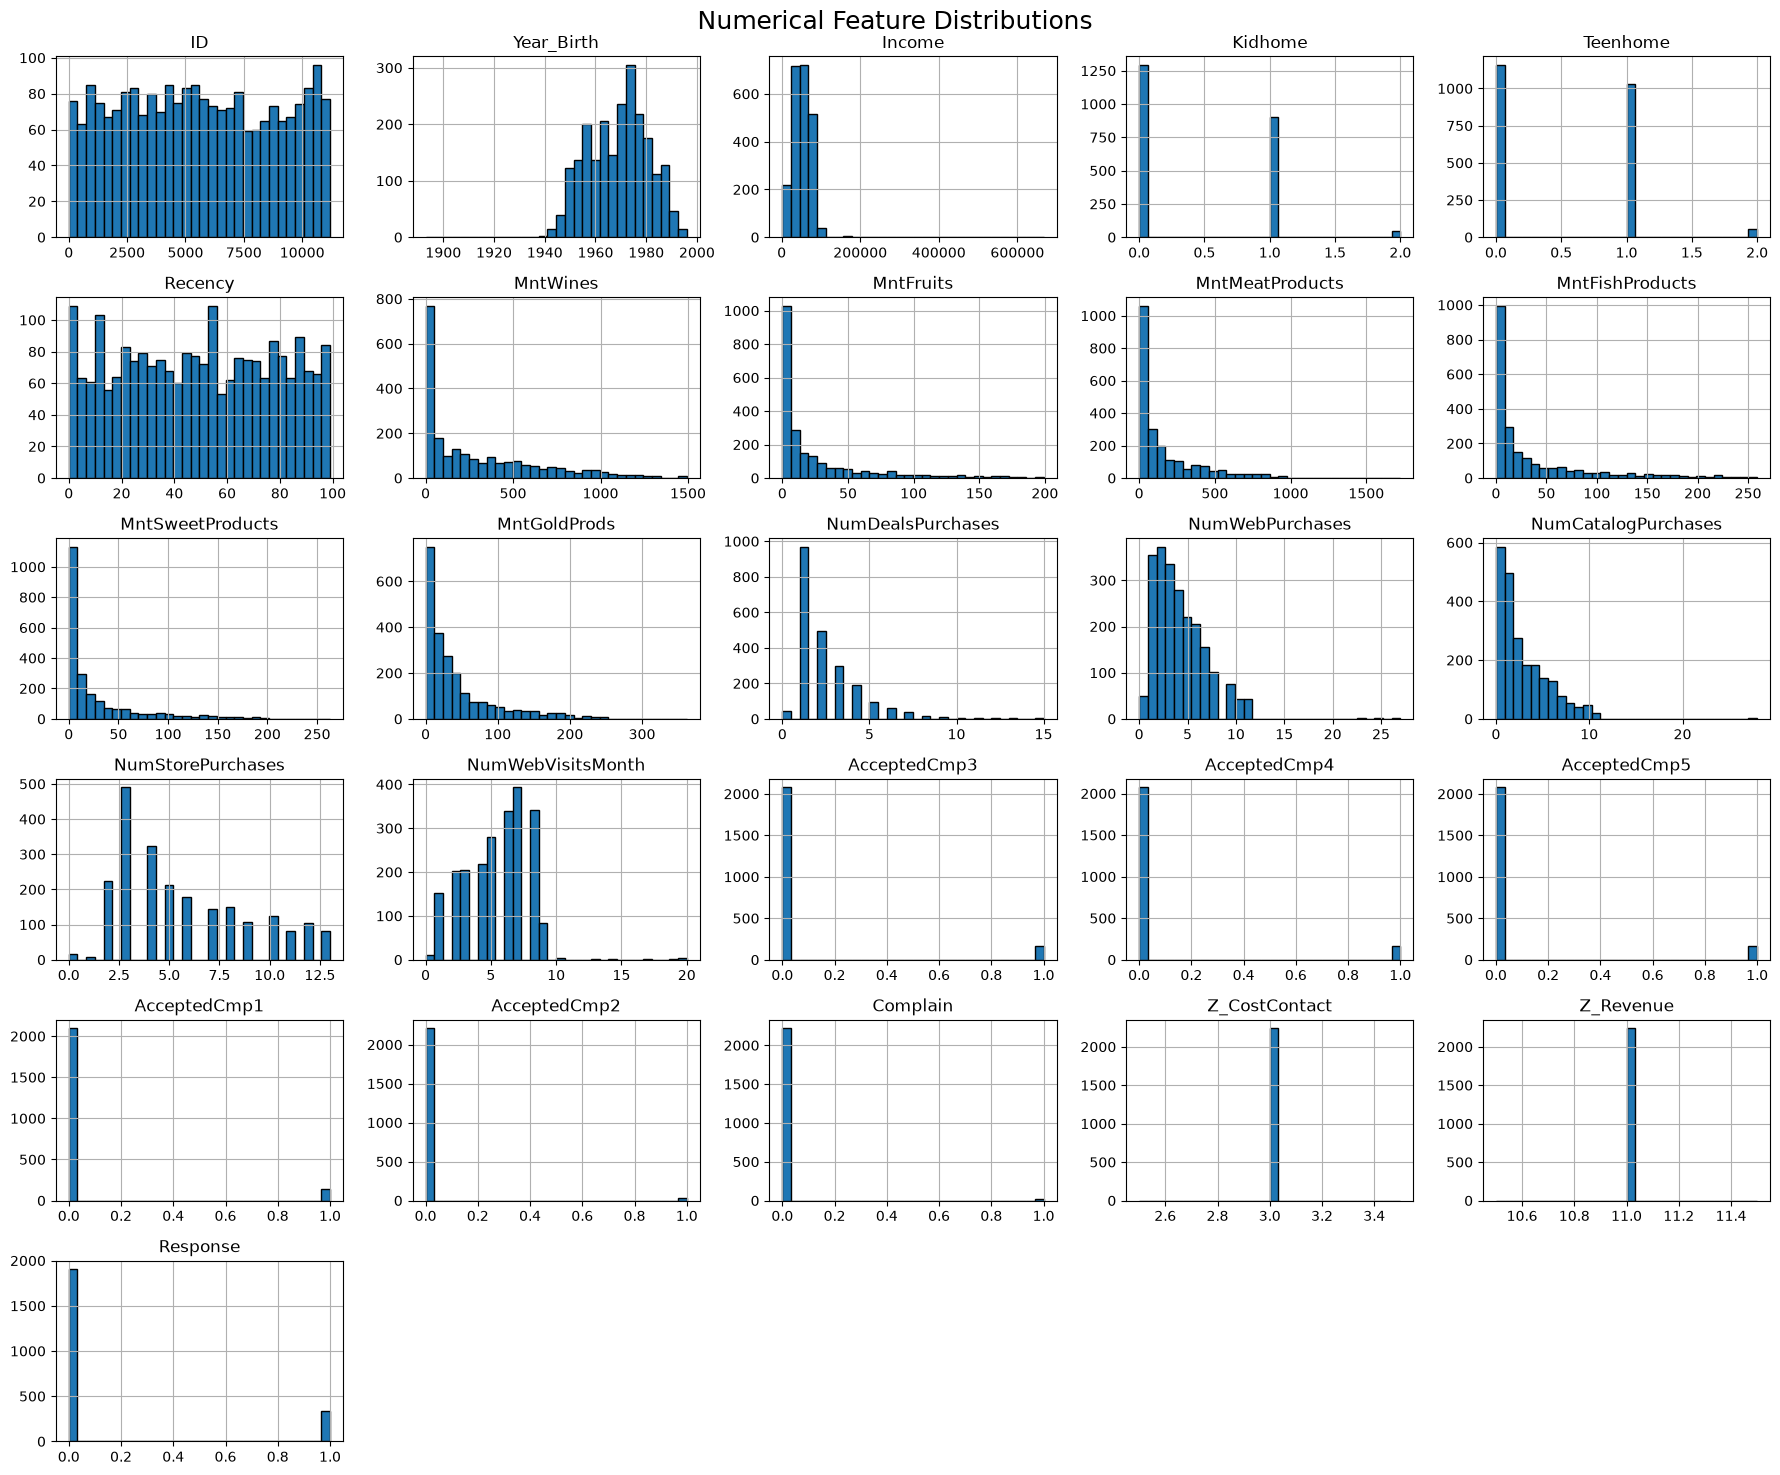

In [27]:
#Numerical feature distributions

numeric_cols = df.select_dtypes(
    include=np.number
).columns

df[numeric_cols].hist(
    figsize=(18, 15),
    bins=30,
    edgecolor='black'
)

plt.suptitle(
    "Numerical Feature Distributions",
    fontsize=18
)

plt.tight_layout()
plt.show()

In [28]:
#Categorical feature distributions

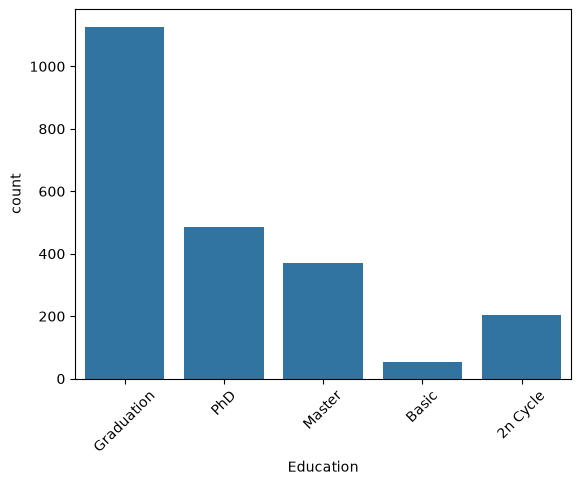

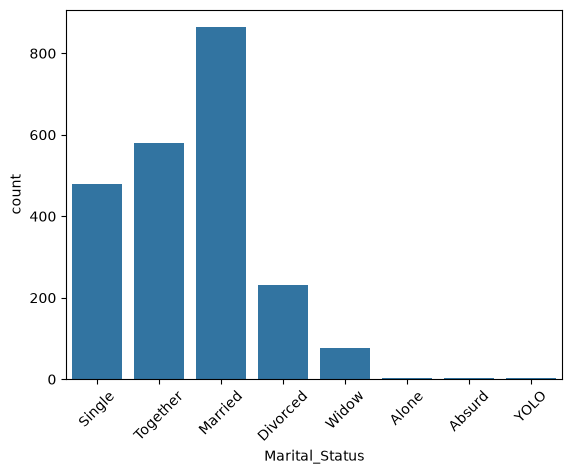

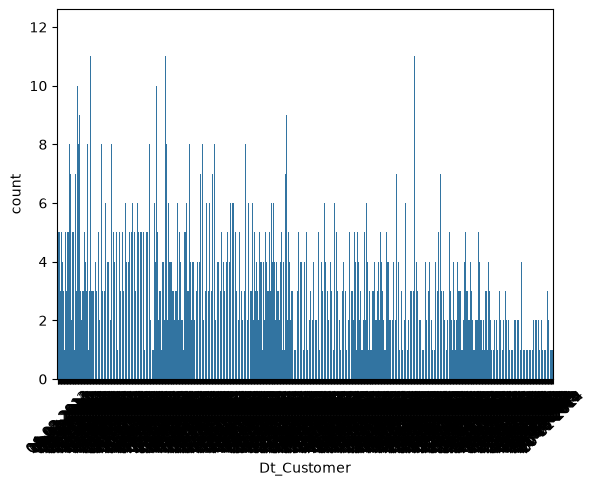

In [29]:


categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    sns.countplot(data=df, x=col)
    plt.xticks(rotation=45)
    plt.show()


In [30]:
# Bivariate and multivariate analysis
# Correlation heatmap

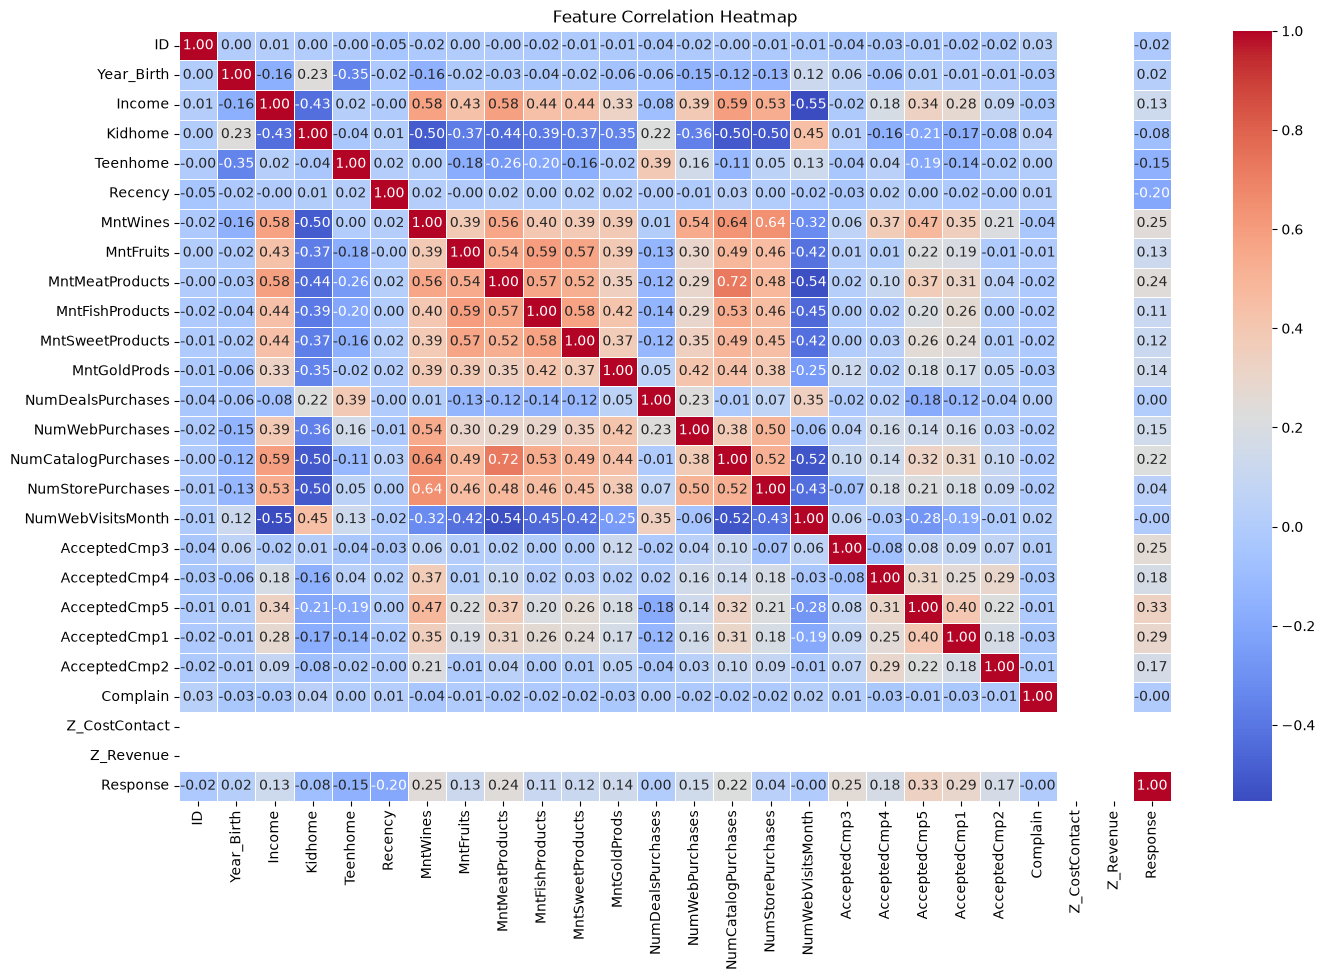

In [31]:
plt.figure(figsize=(16, 10))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap")

plt.show()

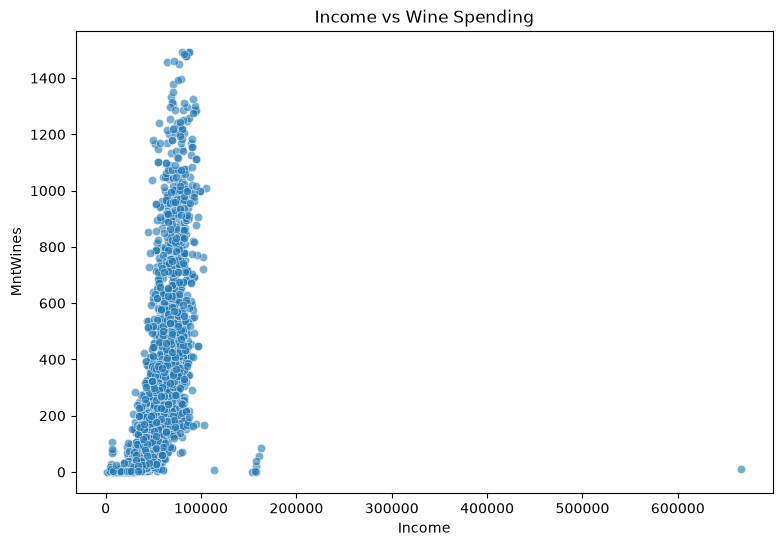

In [32]:
#Income vs spending
if 'Income' in df.columns and 'MntWines' in df.columns:

    plt.figure(figsize=(9, 6))

    sns.scatterplot(
        data=df,
        x='Income',
        y='MntWines',
        alpha=0.6
    )

    plt.title("Income vs Wine Spending")

    plt.show()

In [34]:
## Feature Engineering

# Calculate customer age
df['Age'] = 2026 - df['Year_Birth']

# Total children
df['Children'] = df['Kidhome'] + df['Teenhome']

# Total spending
df['Total_Spending'] = (
    df['MntWines'] +
    df['MntFruits'] +
    df['MntMeatProducts'] +
    df['MntFishProducts'] +
    df['MntSweetProducts'] +
    df['MntGoldProds']
)

# Total purchases
df['Total_Purchases'] = (
    df['NumDealsPurchases'] +
    df['NumWebPurchases'] +
    df['NumCatalogPurchases'] +
    df['NumStorePurchases']
)

df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Children,Total_Spending,Total_Purchases
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,0,0,0,3,11,1,69,0,1617,25
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,0,0,0,3,11,0,72,2,27,6
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,0,0,0,3,11,0,61,0,776,21
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,0,0,0,3,11,0,42,1,53,8
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,0,0,0,3,11,0,45,1,422,19


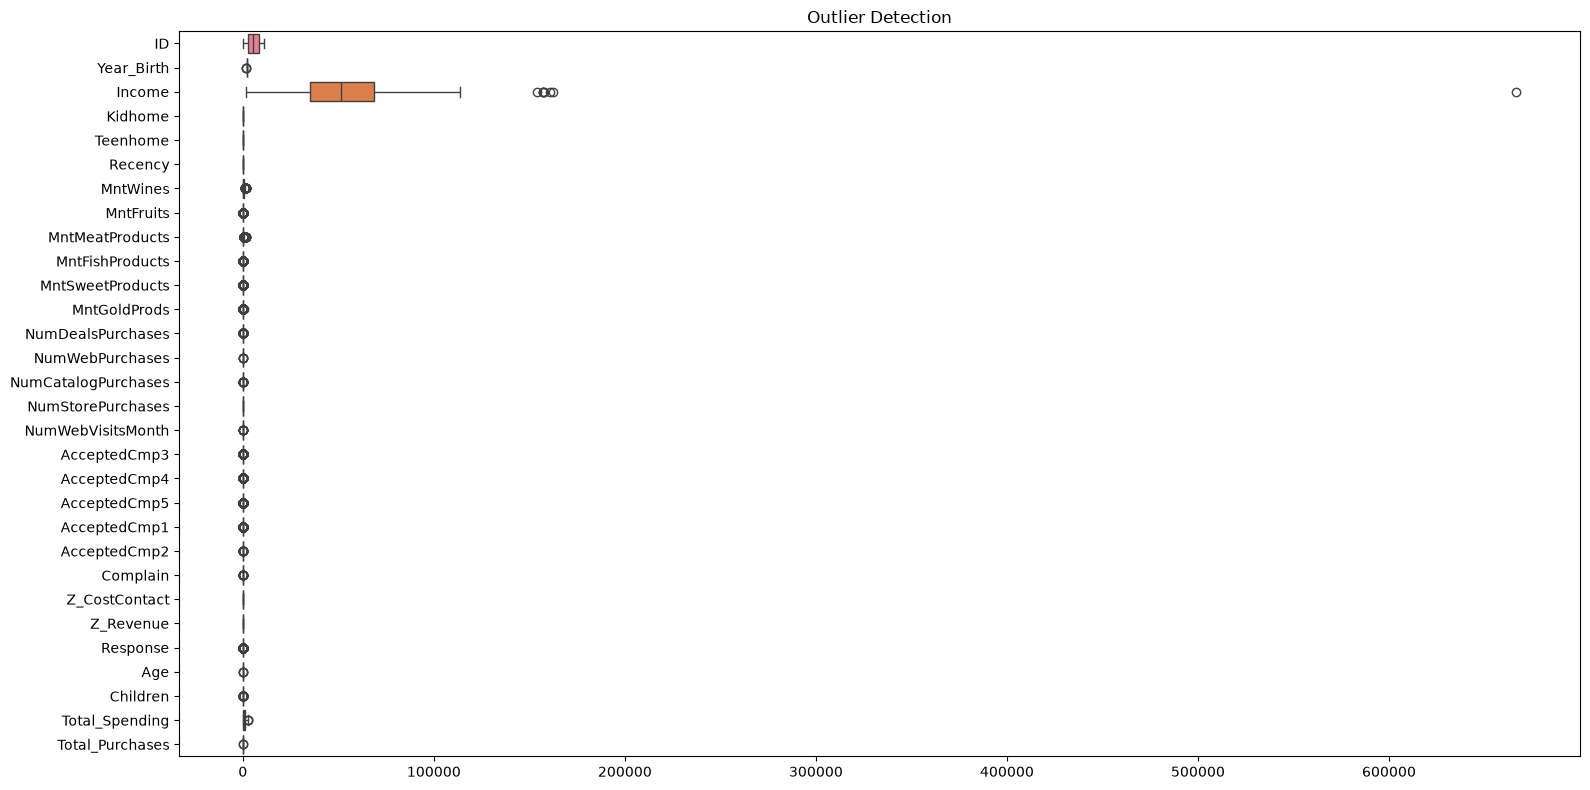

In [35]:
numeric_cols = df.select_dtypes(
    include=np.number
).columns

plt.figure(figsize=(16, 8))

sns.boxplot(
    data=df[numeric_cols],
    orient='h'
)

plt.title("Outlier Detection")

plt.tight_layout()

plt.show()

In [44]:
##We will use IQR-based capping instead of blindly deleting customers.
for col in numeric_cols:

    Q1 = df[col].quantile(0.25)

    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR

    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(
        lower=lower,
        upper=upper
    )

print("Outlier capping completed!")

Outlier capping completed!


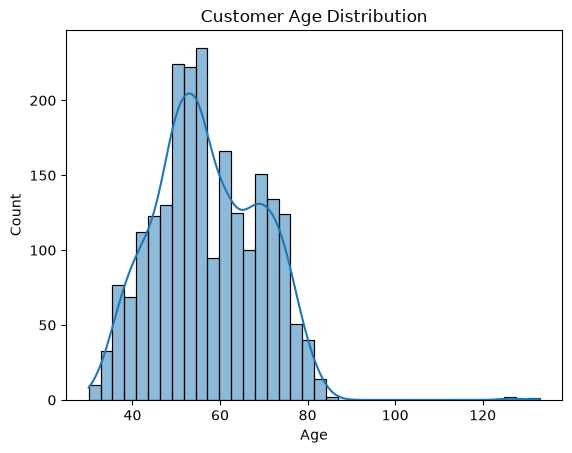

In [36]:
sns.histplot(df['Age'], kde=True)
plt.title("Customer Age Distribution")
plt.show()

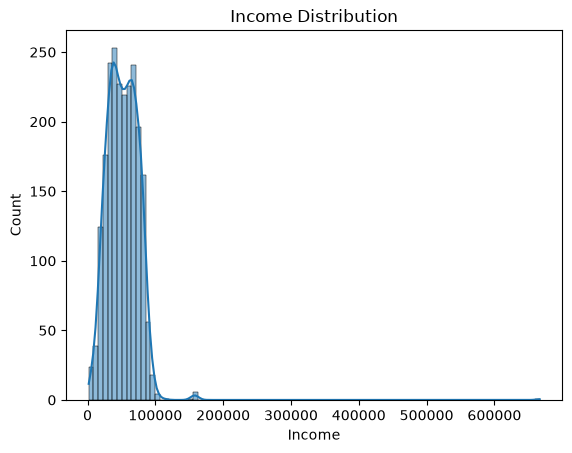

In [37]:
sns.histplot(df['Income'], kde=True)
plt.title("Income Distribution")
plt.show()

In [ ]:
# Select features for clustering
# We will use customer age, income, spending and purchasing behavior.

In [39]:
features = [
    'Age',
    'Income',
    'Total_Spending',
    'Total_Purchases',
    'Recency',
    'Children'
]

X = df[features]

X.head()

,Age,Income,Total_Spending,Total_Purchases,Recency,Children
0,69,58138.0,1617,25,58,0
1,72,46344.0,27,6,38,2
2,61,71613.0,776,21,26,0
3,42,26646.0,53,8,26,1
4,45,58293.0,422,19,94,1


In [40]:
# Feature scaling
# K-Means needs scaling because features have different range

In [46]:
# Elbow method
# Find the optimal number of clusters.

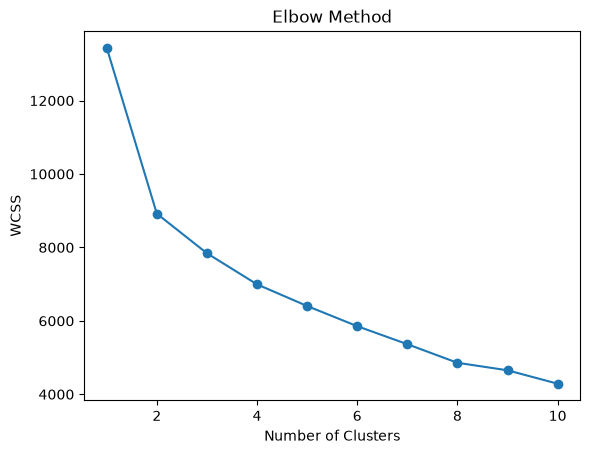

In [49]:
from sklearn.impute import SimpleImputer


# 1. Fill missing values with the median
imputer = SimpleImputer(strategy='median')
X_clean = imputer.fit_transform(X)

# 2. Scale the clean data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)

# 3. Run your Elbow Method loop
wcss = []
for i in range(1, 11):
    model = KMeans(n_clusters=i, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()


In [50]:
##Silhouette score

In [51]:
for i in range(2, 11):

    model = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    print("Clusters:", i, "Score:", round(score, 3))

Clusters: 2 Score: 0.315
Clusters: 3 Score: 0.239
Clusters: 4 Score: 0.211
Clusters: 5 Score: 0.202
Clusters: 6 Score: 0.217
Clusters: 7 Score: 0.227
Clusters: 8 Score: 0.216
Clusters: 9 Score: 0.202
Clusters: 10 Score: 0.219


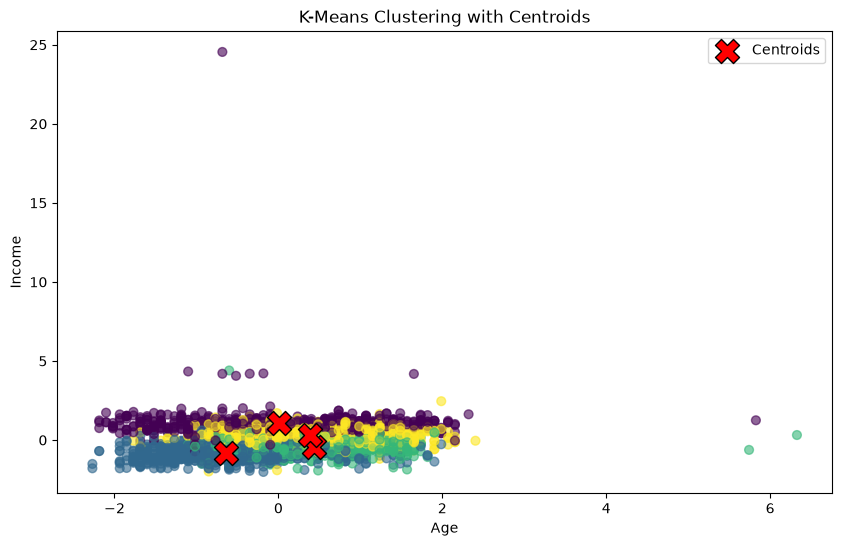

In [63]:
# Get cluster labels
labels = kmeans.labels_

# Get centroid points
centroids = kmeans.cluster_centers_

# Scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=labels,
    cmap='viridis',
    s=40,
    alpha=0.6
)

# Plot centroids
plt.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker='X',
    s=300,
    c='red',
    edgecolor='black',
    label='Centroids'
)

plt.title("K-Means Clustering with Centroids")

plt.xlabel(features[0])

plt.ylabel(features[1])

plt.legend()

plt.show()

In [52]:
# Train K-Means model
# After checking the Elbow graph and Silhouette scores, select the appropriate K.

In [53]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

df.head()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response,Age,Children,Total_Spending,Total_Purchases,Cluster
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,0,0,3,11,0,69,0.0,1617.0,25.0,0
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,0,0,3,11,0,72,2.0,27.0,6.0,2
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,0,0,3,11,0,61,0.0,776.0,21.0,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,0,0,3,11,0,42,1.0,53.0,8.0,1
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,0,0,3,11,0,45,1.0,422.0,19.0,3


In [54]:
#Model evaluation

In [55]:
labels = df['Cluster']

print("Silhouette Score:",
      silhouette_score(X_scaled, labels))

print("Davies Bouldin Score:",
      davies_bouldin_score(X_scaled, labels))

print("Calinski Harabasz Score:",
      calinski_harabasz_score(X_scaled, labels))

Silhouette Score: 0.21140167051170444
Davies Bouldin Score: 1.668458564825368
Calinski Harabasz Score: 686.8586042550652


In [56]:
#Visualize clusters using PCA

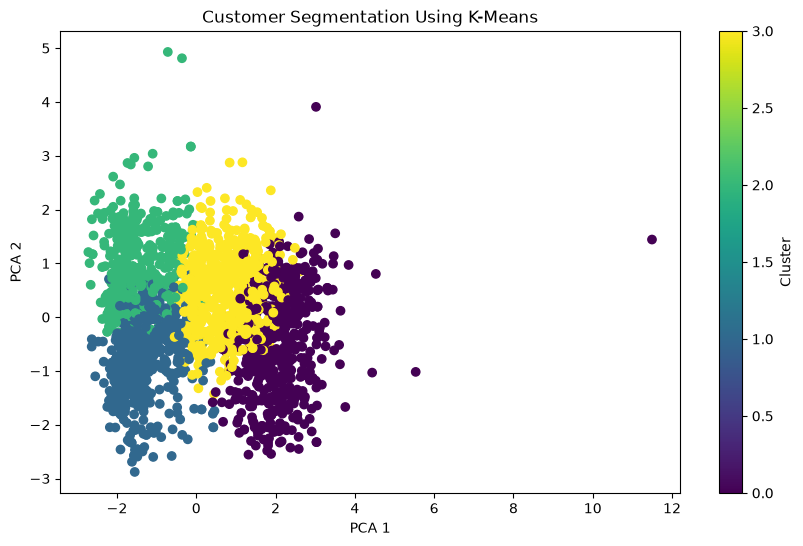

In [57]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=df['Cluster'],
    cmap='viridis'
)

plt.xlabel("PCA 1")

plt.ylabel("PCA 2")

plt.title("Customer Segmentation Using K-Means")

plt.colorbar(label="Cluster")

plt.show()

In [58]:
# Cluster analysis
# Understand the characteristics of each customer group.

In [59]:
cluster_analysis = df.groupby('Cluster')[
    features
].mean()

display(cluster_analysis)

,Age,Income,Total_Spending,Total_Purchases,Recency,Children
Cluster,,,,,,
0,57.152672,77197.127885,1433.345181,20.493321,51.507634,0.106870
1,49.485030,31091.859304,110.538922,7.931138,48.591317,0.805389
2,62.288684,41638.975352,123.521940,9.321016,51.159353,1.927252
3,61.847154,59969.536946,778.126829,21.483740,46.185366,1.095935


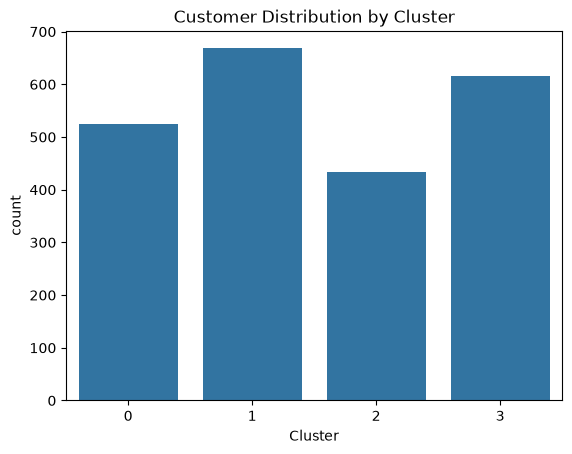

In [60]:
sns.countplot(
    data=df,
    x='Cluster'
)

plt.title("Customer Distribution by Cluster")

plt.show()

In [61]:
df.to_csv(
    "customer_segments_01.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [62]:
import joblib

joblib.dump(kmeans, "kmeans_model.pkl")

joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']